# Setup

This section establish a reproducible, hardware environment and a consistent data interface which is needed for medical imaging experiments. Reproducibility control ensure that training and evaluation can be repeated with minimal variance, which is critical when comparing architectural choices or preprocessing setting in a high risk domain like cancer detection. Hardware detection selects CUDA when available which is to ensure that it uses GPU to improve the workload speed. the path configuration ensures a clear split for training, validation and testing, which helps to prevent data leakage.

In [ ]:
# ==============================#
# Step 0: Imports & Reproducibility
# ==============================#
import os
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, precision_recall_fscore_support)

# Reproducibility
def set_seed(seed: int = 42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


# ==============================#
# Step 1: Paths & Basic Checks
# ==============================#
DATA_ROOT = "/content/drive/Othercomputers/My Laptop/FYPFinal/Breast Cancer Better"

train_dir = Path(DATA_ROOT) / "train"
valid_dir = Path(DATA_ROOT) / "valid"
test_dir  = Path(DATA_ROOT) / "test"

for p in [train_dir, valid_dir, test_dir]:
    if not p.exists():
        raise FileNotFoundError(f"Missing required directory: {p}")

print("Found dirs:")
print(" -", train_dir)
print(" -", valid_dir)
print(" -", test_dir)

CLASS_NAMES = {0: "non-cancer", 1: "cancer"}


Device: cuda
Found dirs:
 - /content/drive/Othercomputers/My Laptop/FYPFinal/Breast Cancer Better/train
 - /content/drive/Othercomputers/My Laptop/FYPFinal/Breast Cancer Better/valid
 - /content/drive/Othercomputers/My Laptop/FYPFinal/Breast Cancer Better/test


# Preprocessing (background removal + transforms + visualization)

This preprocessing stage standardizes mammograms before model training, with the primary aim of removing background handwriting and harmonizing background color while preserving parenchymal details. An Otsu-derived threshold is then employed to automatically estimate the background polarity, enabling the formation of a breast mask that distinguishes tissue from non-diagnostic regions. The mask is then subsequenly refined using morphological operations, with additional edge recovery steps to mitigate potential erosion of tisue boundaries. By focusing on background standarization rather than cropping or rigid alighment, the original canvas is retained, ensuring that convolutional neural networks learn tissue patterns rather than being influenced by acquisition artifacts. Following masking, images are then resized to a fixed resolution and normalized using ImageNet statistics to align with the distribution expected by pretrained encoders. Finally, light geometric and photometric augmentations are applied to imrpove generalization and reduce overfitting, therefore enchancing the robustness of the learning process.

In [ ]:
# ==============================#
# Step 2: Tunable BG removal (anti-erosion) + Transforms
# ==============================#
import cv2
from PIL import Image
import torchvision.transforms.functional as TF

# ---- EASY-EDIT PARAMETERS  ----
blur_ksize      = 0.5
morph_ksize     = 0.1
min_area_frac   = 0.01

# Anti-erosion controls:
use_blur        = True
close_iters     = 1      # morphological CLOSE iterations hole fill
open_iters      = 1      # morphological OPEN iterations remove specks
edge_recover_px = 1      # post-mask dilation
threshold_bias  = -26    # shift Otsu threshold units Negatives preserve more tissue
border_band     = 5      # pixels of border used to detect white vs black background

# ------------------------------------------------------

def _odd_kernel(x, minimum=3):
    """Convert any number to a valid odd integer >= minimum (for OpenCV kernels)."""
    x = int(round(float(x)))
    if x < minimum: x = minimum
    if x % 2 == 0: x += 1
    return x

# Sanitize kernels once and print effective values
_blur_ksize  = _odd_kernel(blur_ksize)
_morph_ksize = _odd_kernel(morph_ksize)
print(f"[BG params] blur_ksize={_blur_ksize}, morph_ksize={_morph_ksize}, "
      f"min_area_frac={min_area_frac}, use_blur={use_blur}, "
      f"close_iters={close_iters}, open_iters={open_iters}, "
      f"edge_recover_px={edge_recover_px}, threshold_bias={threshold_bias}, "
      f"border_band={border_band}")

class RemoveBackgroundNoCrop:
    """
    Zero-out background while preserving image size.
    Anti-erosion features: optional blur, adjustable morphology, threshold bias, and rim recovery.
    """
    def __init__(self,
                 blur_ksize, morph_ksize, min_area_frac,
                 use_blur=True, close_iters=1, open_iters=1,
                 edge_recover_px=0, threshold_bias=0, border_band=10):
        self.blur_ksize  = _odd_kernel(blur_ksize)
        self.morph_ksize = _odd_kernel(morph_ksize)
        self.min_area_frac = float(min_area_frac)

        self.use_blur = bool(use_blur)
        self.close_iters = int(close_iters)
        self.open_iters  = int(open_iters)
        self.edge_recover_px = int(edge_recover_px)
        self.threshold_bias  = int(threshold_bias)
        self.border_band    = int(border_band)

    def __call__(self, img: Image.Image) -> Image.Image:
        # Force grayscale uint8
        if img.mode != "L":
            img = img.convert("L")
        g = np.array(img, dtype=np.uint8)

        # Detect background polarity from border
        b = self.border_band
        b = max(1, min(b, min(g.shape)//4))
        border = np.concatenate([g[:b,:].ravel(), g[-b:,:].ravel(), g[:,:b].ravel(), g[:,-b:].ravel()])
        bg_is_white = border.mean() > 127  # True => white background

        g_in = cv2.GaussianBlur(g, (self.blur_ksize, self.blur_ksize), 0) if self.use_blur else g

        # Compute an Otsu baseline threshold, then apply a bias
        # compute with non-inverted Otsu to get a stable threshold scalar.
        thr_otsu, _ = cv2.threshold(g_in, 0, 255, cv2.THRESH_OTSU)
        thr = int(np.clip(thr_otsu + self.threshold_bias, 0, 255))

        # Build mask using biased threshold with correct polarity
        if bg_is_white:
            # breast darker than white bg -> keep pixels below threshold
            mask = (g_in < thr).astype(np.uint8) * 255
        else:
            # breast brighter than black bg -> keep pixels above threshold
            mask = (g_in > thr).astype(np.uint8) * 255

        # Morphological cleanup (gentle by default)
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (self.morph_ksize, self.morph_ksize))
        if self.close_iters > 0:
            mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=self.close_iters)
        if self.open_iters > 0:
            mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  k, iterations=self.open_iters)

        # Keep largest component (if not tiny vs image)
        num, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
        if num > 1:
            areas = stats[1:, cv2.CC_STAT_AREA]
            largest_idx = 1 + int(np.argmax(areas))
            largest_area = stats[largest_idx, cv2.CC_STAT_AREA]
            if largest_area >= self.min_area_frac * (g.shape[0] * g.shape[1]):
                mask_keep = (labels == largest_idx).astype(np.uint8) * 255
            else:
                mask_keep = mask  # fallback if segmentation seems dubious
        else:
            mask_keep = mask

        if self.edge_recover_px > 0:
            kr = 2 * self.edge_recover_px + 1  # ensure odd
            k_rec = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kr, kr))
            mask_keep = cv2.dilate(mask_keep, k_rec, iterations=1)

        # Apply mask (background -> 0) and return 3-channel RGB
        g_fg = cv2.bitwise_and(g, g, mask=mask_keep)
        g3 = np.stack([g_fg, g_fg, g_fg], axis=-1)
        return Image.fromarray(g3)

        # return Image.fromarray(g3, mode="RGB")


# Build transforms with your current settings
IMG_SIZE = 224
bg_remove = RemoveBackgroundNoCrop(
    blur_ksize=_blur_ksize, morph_ksize=_morph_ksize, min_area_frac=min_area_frac,
    use_blur=use_blur, close_iters=close_iters, open_iters=open_iters,
    edge_recover_px=edge_recover_px, threshold_bias=threshold_bias, border_band=border_band
)

train_tfms = transforms.Compose([
    bg_remove,
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(7),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])

eval_tfms = transforms.Compose([
    bg_remove,
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])


[BG params] blur_ksize=3, morph_ksize=3, min_area_frac=0.01, use_blur=True, close_iters=1, open_iters=1, edge_recover_px=1, threshold_bias=-26, border_band=5


# Visualization helpers

To ensure that the preprocessing achieves the intended effect without discarding relevant features, visualization helpers are integrated into the pipeline. The function samples mammograms from each class and displays them before and after the background removal, with the original images shown on the top row and their processed counterpart below. By reviewing 20 examples side by side, it made it possible to verify that handwriting, borders, and background inconsistencies are removed and standarized while parenchymal structures remain intact. This step is not part of the learning process, but it plays a part in sanity checking of the preprocessing pipeline. By including the visualization at this stage, it ensures that the subsequent CNN training is grounded on tissue level features rather than artifacts, aligning preprocessing outcomes with the clinical objective of robust breast cancer detection.

Class 0 examples:


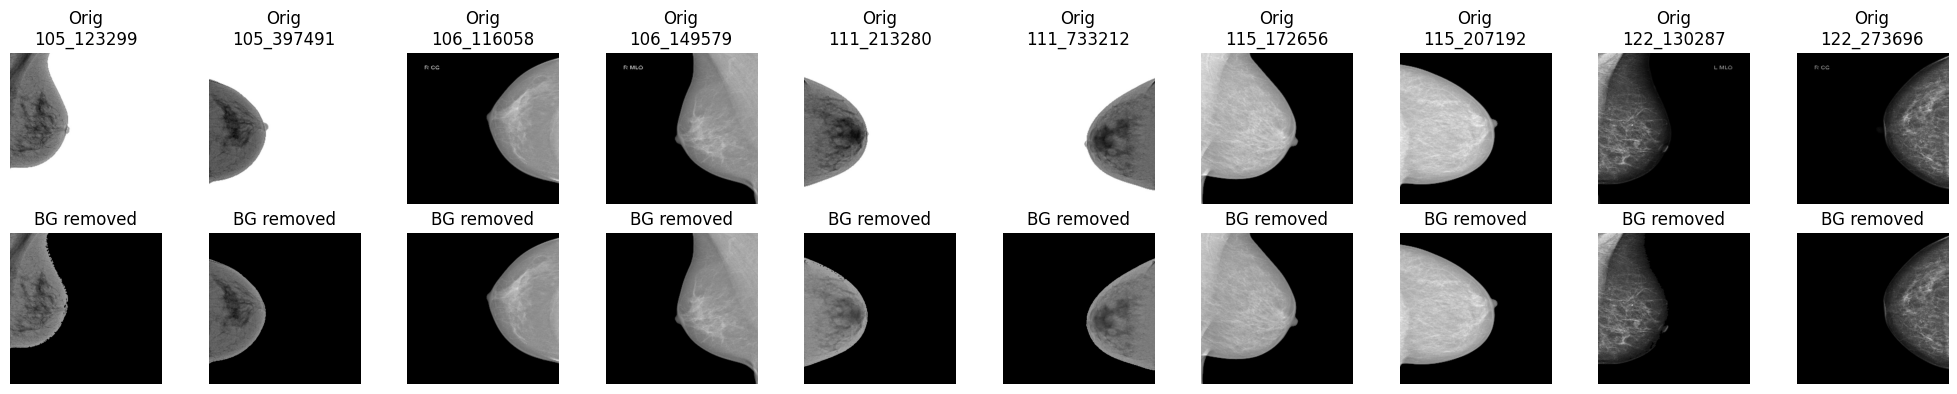

Class 1 examples:


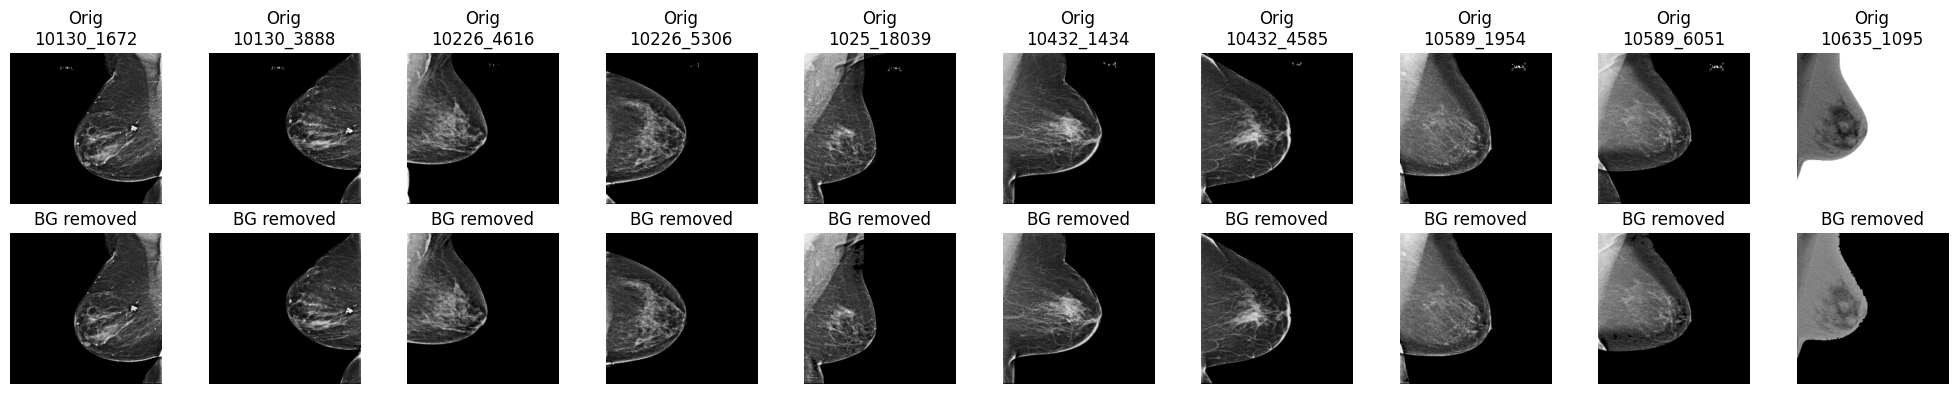

In [ ]:
# ==============================#
# Step 3: 20 examples (Original vs BG-removed)
# ==============================#
from PIL import Image

def show_many_examples(class_folder, n=10):
    files = sorted(list(Path(class_folder).glob("*.*")))[:n]
    if len(files) == 0:
        print(f"No images found in {class_folder}")
        return
    fig, axes = plt.subplots(2, len(files), figsize=(2*len(files), 4))
    for i, fp in enumerate(files):
        raw = Image.open(fp).convert("L")
        masked = bg_remove(raw)

        axes[0, i].imshow(raw, cmap="gray")
        axes[0, i].set_title(f"Orig\n{fp.stem[:10]}")
        axes[0, i].axis("off")

        axes[1, i].imshow(masked, cmap="gray")
        axes[1, i].set_title("BG removed")
        axes[1, i].axis("off")
    plt.tight_layout(); plt.show()

print("Class 0 examples:")
show_many_examples(train_dir/"0", n=10)

print("Class 1 examples:")
show_many_examples(train_dir/"1", n=10)


# Datasets & dataloaders (bound to current bg settings)



This stage prepares the mammogram data for efficient use in model training and evaluation. The ImageGolder utility is employed to automatically infer class labels from the directory structure, ensuring a consistent mapping between folders names and class indices. To maintain alignment with the preprocessing pipeline, the dataset are bound to the background removal and transform setting defined earlier, ensuring that all the images that enters the CNNs model are all standardized, artifact removed, resized, and normalized. A counting function is then used to verify the class distribution in all the splits, which shows the imbalance of the dataset. In this case, all the 3 sets contains similar number of cancer and non-cancer samples, the need of stratified sampling is not required.

For training stability, the data is loaded into small batches and shuffled into epoch to prevent the model from memorizing sample order. Validation and test loaders are kept deterministic to ensure reproducible evaluation. The use of pin_memory and num_worker optimizes the output and reduces I/O bottlenecks, making the pipeloine more efficient for GPU environments. Thus creating a robust and reproducible pipleline ensuring that subsequent models learn similar input from the preprocessed pipeline while having separate subsets of data.


In [ ]:
# ==============================#
# Step 4: Datasets & Dataloaders (train + valid combined)
# ==============================#
from torch.utils.data import ConcatDataset, DataLoader
from torchvision import datasets

# 1) Build datasets
#    - Train uses train_tfms (augmentations)
#    - Valid will be re-wrapped with train_tfms so it contributes to training with the same policy
#    - Test stays eval_tfms (no augmentations)
train_ds = datasets.ImageFolder(root=str(train_dir), transform=train_tfms)
valid_ds_eval = datasets.ImageFolder(root=str(valid_dir), transform=eval_tfms)      # for counting only
valid_ds_train = datasets.ImageFolder(root=str(valid_dir), transform=train_tfms)    # for combining into training
test_ds  = datasets.ImageFolder(root=str(test_dir),  transform=eval_tfms)

# 2) Combine train + valid for final training
combined_train_ds = ConcatDataset([train_ds, valid_ds_train])

# 3) Utility: count targets for an ImageFolder
def count_targets_imgfolder(ds: datasets.ImageFolder):
    counts = {c: 0 for c in ds.class_to_idx.values()}
    # ds.samples is list[(path, class_idx), ...]
    for _, y in ds.samples:
        counts[y] += 1
    return counts

# 4) Compute counts
train_counts  = count_targets_imgfolder(train_ds)
valid_counts  = count_targets_imgfolder(valid_ds_eval)  # count using non-aug wrapped version
test_counts   = count_targets_imgfolder(test_ds)
# Sum train+valid for combined
combined_counts = {k: train_counts.get(k, 0) + valid_counts.get(k, 0) for k in train_counts.keys()}

# 5) Print mappings & counts
print("Class-to-index:", train_ds.class_to_idx)

def pretty_counts(raw_counts):
    return {CLASS_NAMES[k]: v for k, v in sorted(raw_counts.items(), key=lambda kv: kv[0])}

print("Train counts:",    pretty_counts(train_counts))
print("Valid counts:",    pretty_counts(valid_counts))
print("Combined counts:", pretty_counts(combined_counts))
print("Test  counts:",    pretty_counts(test_counts))

# 6) Dataloaders
BATCH_SIZE   = 16
NUM_WORKERS  = 2

train_loader = DataLoader(combined_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
# No separate valid_loader now (merged it into training)
valid_loader = None

test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print(f"[INFO] Combined training samples: {sum(len(d) for d in combined_train_ds.datasets)}")
print(f"[INFO] Test samples: {len(test_ds)}")


Class-to-index: {'0': 0, '1': 1}
Train counts: {'non-cancer': 1569, 'cancer': 803}
Valid counts: {'non-cancer': 448, 'cancer': 227}
Combined counts: {'non-cancer': 2017, 'cancer': 1030}
Test  counts: {'non-cancer': 208, 'cancer': 128}
[INFO] Combined training samples: 3047
[INFO] Test samples: 336


# Fully Train Individual Models.

#Resnet50

[INFO] Final outputs -> /content/drive/MyDrive/colab_models/simple_run_final
[INFO] Combined class counts: {'non-cancer': 2017, 'cancer': 1030}
[INFO] Class weights (inverse freq): [1.510659395141299, 2.958252427184466]

=== Training resnet50_bestF1_trainvalid_combined ===
[Epoch 01] train_loss=0.7204 train_acc=0.540 | test_loss=0.6675 test_acc=0.571
[Epoch 02] train_loss=0.6784 train_acc=0.595 | test_loss=0.8816 test_acc=0.619
[Epoch 03] train_loss=0.6639 train_acc=0.644 | test_loss=0.6461 test_acc=0.607
[Epoch 04] train_loss=0.6409 train_acc=0.655 | test_loss=0.6268 test_acc=0.649
[Epoch 05] train_loss=0.6417 train_acc=0.666 | test_loss=0.7018 test_acc=0.592
[Epoch 06] train_loss=0.6274 train_acc=0.676 | test_loss=0.6353 test_acc=0.622
[Epoch 07] train_loss=0.6259 train_acc=0.676 | test_loss=0.6068 test_acc=0.682
[Epoch 08] train_loss=0.5966 train_acc=0.705 | test_loss=0.6391 test_acc=0.658
[Epoch 09] train_loss=0.5956 train_acc=0.709 | test_loss=0.6366 test_acc=0.643
[Epoch 10] trai

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb49411d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1664, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1647, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process


[Epoch 13] train_loss=0.5169 train_acc=0.758 | test_loss=0.8270 test_acc=0.607


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb49411d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1664, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1647, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cb49411d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1664, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

[Epoch 14] train_loss=0.5021 train_acc=0.766 | test_loss=0.6145 test_acc=0.711
[Epoch 15] train_loss=0.4874 train_acc=0.775 | test_loss=0.7190 test_acc=0.652
[Epoch 16] train_loss=0.4654 train_acc=0.790 | test_loss=0.6298 test_acc=0.679
[Epoch 17] train_loss=0.4381 train_acc=0.803 | test_loss=0.7504 test_acc=0.690
[Epoch 18] train_loss=0.4381 train_acc=0.805 | test_loss=0.6439 test_acc=0.693
[Epoch 19] train_loss=0.3797 train_acc=0.839 | test_loss=0.7188 test_acc=0.693
[Epoch 20] train_loss=0.3726 train_acc=0.840 | test_loss=0.7705 test_acc=0.682
[Epoch 21] train_loss=0.3395 train_acc=0.856 | test_loss=0.7663 test_acc=0.732
[Epoch 22] train_loss=0.3331 train_acc=0.856 | test_loss=0.7202 test_acc=0.679
[Epoch 23] train_loss=0.3116 train_acc=0.870 | test_loss=0.7543 test_acc=0.690
[Epoch 24] train_loss=0.2784 train_acc=0.885 | test_loss=0.7827 test_acc=0.637
[Epoch 25] train_loss=0.2645 train_acc=0.898 | test_loss=0.8461 test_acc=0.685
[Epoch 26] train_loss=0.2404 train_acc=0.905 | test_

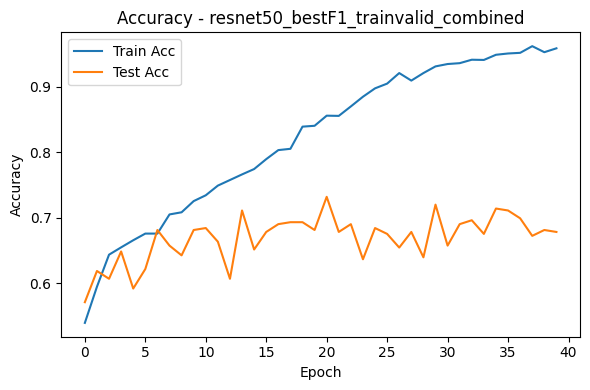

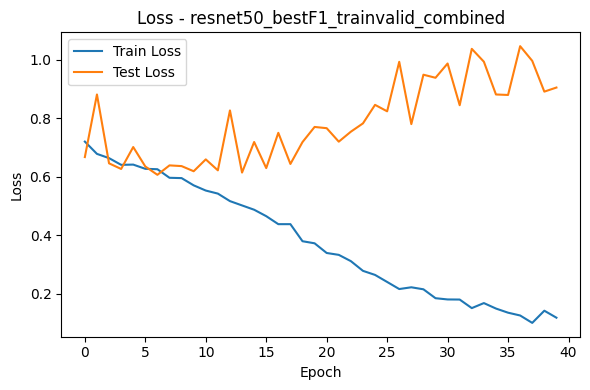


=== FINAL TEST METRICS (resnet50_bestF1_trainvalid_combined) ===
 accuracy: 0.6726
precision: 0.5738
   recall: 0.5469
       f1: 0.5600
      auc: 0.7462
Confusion Matrix (rows=true, cols=pred):
 [[156  52]
 [ 58  70]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/resnet50_bestF1_trainvalid_combined_test_metrics.csv

=== Training resnet50_bestACC_trainvalid_combined ===
[Epoch 01] train_loss=0.6517 train_acc=0.638 | test_loss=0.7440 test_acc=0.533
[Epoch 02] train_loss=0.6285 train_acc=0.671 | test_loss=0.6568 test_acc=0.643
[Epoch 03] train_loss=0.6067 train_acc=0.682 | test_loss=0.6835 test_acc=0.634
[Epoch 04] train_loss=0.6054 train_acc=0.678 | test_loss=0.6267 test_acc=0.655
[Epoch 05] train_loss=0.5811 train_acc=0.706 | test_loss=0.5937 test_acc=0.658
[Epoch 06] train_loss=0.5593 train_acc=0.713 | test_loss=0.6160 test_acc=0.664
[Epoch 07] train_loss=0.5479 train_acc=0.728 | test_loss=0.6271 test_acc=0.670
[Epoch 08] train_loss=0.5331 train

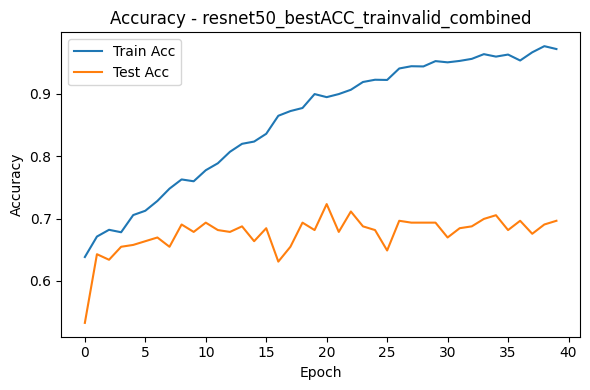

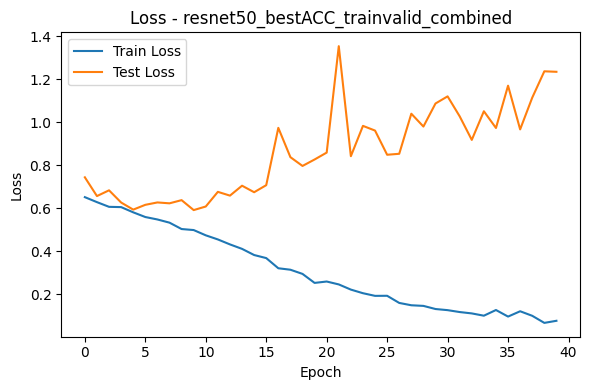


=== FINAL TEST METRICS (resnet50_bestACC_trainvalid_combined) ===
 accuracy: 0.6905
precision: 0.6277
   recall: 0.4609
       f1: 0.5315
      auc: 0.7367
Confusion Matrix (rows=true, cols=pred):
 [[173  35]
 [ 69  59]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/resnet50_bestACC_trainvalid_combined_test_metrics.csv

=== Side-by-side (Final Test) ===
 accuracy: BestF1=0.6726 | BestACC=0.6905
precision: BestF1=0.5738 | BestACC=0.6277
   recall: BestF1=0.5469 | BestACC=0.4609
       f1: BestF1=0.5600 | BestACC=0.5315
      auc: BestF1=0.7462 | BestACC=0.7367


In [ ]:
# ==============================#
# Step 5.1: Final train (ResNet50 Best-F1 & Best-Accuracy) + per-epoch Test curves
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix)
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
from pathlib import Path

# ---- Save directory ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run_final')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Final outputs -> {SAVE_DIR.resolve()}")

# ---- Training budget ----
MAX_EPOCHS = 40
LOG_EVERY  = 0      # print batch progress
USE_SCHED  = True   # LR decay on train loss plateau

# ---- Two hypertuned configs ----
CFG_BEST_F1 = {
    "tag": "resnet50_bestF1_trainvalid_combined",
    "model_name": "resnet50",
    "freeze": "train_all",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.6,
    "class_weighting": True,
}
CFG_BEST_ACC = {
    "tag": "resnet50_bestACC_trainvalid_combined",
    "model_name": "resnet50",
    "freeze": "freeze_block1",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.4,
    "class_weighting": False,
}
ALL_CFGS = [CFG_BEST_F1, CFG_BEST_ACC]

# -------------------- Model & Freeze -------------------- #
def build_model(dropout_p: float = 0.5) -> nn.Module:
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    in_feats = m.fc.in_features
    m.fc = nn.Sequential(nn.Dropout(p=float(dropout_p)), nn.Linear(in_feats, 2))
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str):
    for p in model.parameters():
        p.requires_grad = True
    if mode == "freeze_block1":
        for p in list(model.conv1.parameters()) + list(model.bn1.parameters()) + list(model.layer1.parameters()):
            p.requires_grad = False
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

# -------------------- Class Weights (from combined counts) -------------------- #
def count_targets_imgfolder(ds):
    counts = {c: 0 for c in ds.class_to_idx.values()}
    for _, y in ds.samples: counts[y] += 1
    return counts

def get_combined_class_weights():
    c_train = count_targets_imgfolder(train_ds)
    c_valid = count_targets_imgfolder(valid_ds_eval)
    combined = {k: c_train.get(k, 0) + c_valid.get(k, 0) for k in c_train.keys()}
    total = sum(combined.values())
    weights = [total / max(1, combined[c]) for c in sorted(combined.keys())]
    print("[INFO] Combined class counts:", {CLASS_NAMES[k]: v for k, v in sorted(combined.items())})
    print("[INFO] Class weights (inverse freq):", weights)
    return torch.tensor(weights, dtype=torch.float, device=DEVICE)

COMBINED_CLASS_WEIGHTS = get_combined_class_weights()

# -------------------- Train / Eval helpers -------------------- #
def train_one_epoch(model, loader, criterion, optimizer, epoch:int=1):
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for i, (xb, yb) in enumerate(loader, 1):
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

        if LOG_EVERY and (i % LOG_EVERY) == 0:
            print(f"  [Epoch {epoch:02d} | {i:05d} iters] loss={loss.item():.4f}")

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion):
    model.eval()
    loss_sum, seen, correct = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()
        seen += xb.size(0)
    return loss_sum / max(1, seen), correct / max(1, seen)

@torch.no_grad()
def evaluate_test_full(model, loader):
    model.eval()
    all_logits, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        all_logits.append(logits.cpu())
        all_targets.append(yb)
    logits = torch.cat(all_logits)
    y_true = torch.cat(all_targets).numpy()
    y_prob = torch.softmax(logits, dim=1).numpy()[:, 1]
    y_pred = logits.argmax(dim=1).numpy()

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = float('nan')
    cm = confusion_matrix(y_true, y_pred)
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc, "cm": cm}

def run_final_train(cfg):
    print(f"\n=== Training {cfg['tag']} ===")
    model = build_model(dropout_p=cfg["dropout"])
    freeze_strategy(model, cfg["freeze"])

    criterion = nn.CrossEntropyLoss(
        weight=COMBINED_CLASS_WEIGHTS if cfg["class_weighting"] else None
    )
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2) if USE_SCHED else None

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "lr": []}
    best_state = copy.deepcopy(model.state_dict())
    best_train_loss = math.inf

    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, epoch)
        te_loss, te_acc = evaluate_loss_acc(model, test_loader, criterion)  # <-- per-epoch test eval

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        print(f"[Epoch {epoch:02d}] train_loss={tr_loss:.4f} train_acc={tr_acc:.3f} | "
              f"test_loss={te_loss:.4f} test_acc={te_acc:.3f}")

        if scheduler is not None:
            scheduler.step(tr_loss)  # reduce LR if training loss plateaus

        if tr_loss < best_train_loss:
            best_train_loss = tr_loss
            best_state = copy.deepcopy(model.state_dict())

    train_time_min = (time.time() - t0) / 60.0
    print(f"[INFO] Training done in {train_time_min:.2f} min. Best train loss={best_train_loss:.4f}")

    # Load best-by-train-loss
    model.load_state_dict(best_state)

    # Save model
    final_model_path = SAVE_DIR / f"final_{cfg['tag']}.pth"
    torch.save({"state_dict": model.state_dict(), "hparams": cfg, "history": history}, final_model_path)
    print(f"[INFO] Saved final model to: {final_model_path}")

    # ---- Curves: Train vs Test ----
    # Accuracy
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["test_acc"],  label="Test Acc")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"Accuracy - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_acc_train_vs_test.png", dpi=150); plt.show()

    # Loss
    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["test_loss"],  label="Test Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"Loss - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_loss_train_vs_test.png", dpi=150); plt.show()

    # Final Test evaluation (full metrics with AUC/CM)
    test_metrics = evaluate_test_full(model, test_loader)
    print(f"\n=== FINAL TEST METRICS ({cfg['tag']}) ===")
    for k in ["accuracy", "precision", "recall", "f1", "auc"]:
        print(f"{k:>9}: {test_metrics[k]:.4f}")
    print("Confusion Matrix (rows=true, cols=pred):\n", test_metrics["cm"])

    # Save metrics CSV
    import pandas as pd
    pd.DataFrame([test_metrics | {"model": cfg["tag"]}]).to_csv(
        SAVE_DIR / f"{cfg['tag']}_test_metrics.csv", index=False
    )
    print(f"[INFO] Wrote test metrics CSV: {SAVE_DIR / f'{cfg['tag']}_test_metrics.csv'}")

    return test_metrics

# -------------------- Run both configs -------------------- #
metrics_f1  = run_final_train(CFG_BEST_F1)
metrics_acc = run_final_train(CFG_BEST_ACC)

print("\n=== Side-by-side (Final Test) ===")
for k in ["accuracy", "precision", "recall", "f1", "auc"]:
    print(f"{k:>9}: BestF1={metrics_f1[k]:.4f} | BestACC={metrics_acc[k]:.4f}")


# DenseNet121

[INFO] Final outputs -> /content/drive/MyDrive/colab_models/simple_run_final
[INFO] Combined class counts: {'non-cancer': 2017, 'cancer': 1030}
[INFO] Class weights (inverse freq): [1.510659395141299, 2.958252427184466]

=== Training densenet121_bestF1_trainvalid_combined (densenet121) ===
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 88.8MB/s]


[Epoch 01] train_loss=0.7062 train_acc=0.565 | test_loss=0.6876 test_acc=0.542
[Epoch 02] train_loss=0.6750 train_acc=0.605 | test_loss=0.6474 test_acc=0.607
[Epoch 03] train_loss=0.6324 train_acc=0.646 | test_loss=0.6095 test_acc=0.679
[Epoch 04] train_loss=0.6103 train_acc=0.679 | test_loss=0.6331 test_acc=0.646
[Epoch 05] train_loss=0.5871 train_acc=0.701 | test_loss=0.6661 test_acc=0.646
[Epoch 06] train_loss=0.5528 train_acc=0.727 | test_loss=0.5763 test_acc=0.705
[Epoch 07] train_loss=0.5447 train_acc=0.732 | test_loss=0.5842 test_acc=0.693
[Epoch 08] train_loss=0.5248 train_acc=0.744 | test_loss=0.6529 test_acc=0.646
[Epoch 09] train_loss=0.4954 train_acc=0.758 | test_loss=0.5922 test_acc=0.696
[Epoch 10] train_loss=0.4721 train_acc=0.770 | test_loss=0.6607 test_acc=0.667
[Epoch 11] train_loss=0.4455 train_acc=0.791 | test_loss=0.6401 test_acc=0.696
[Epoch 12] train_loss=0.4058 train_acc=0.819 | test_loss=0.6300 test_acc=0.711
[Epoch 13] train_loss=0.3883 train_acc=0.828 | test_

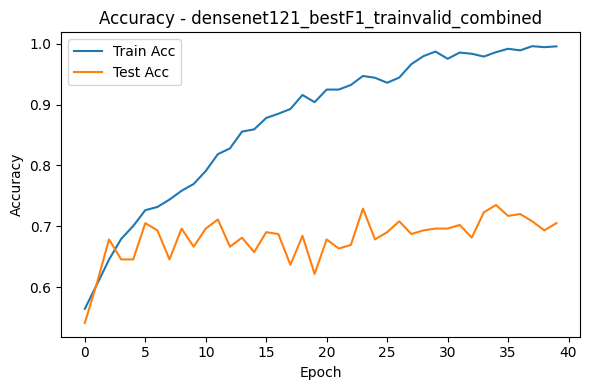

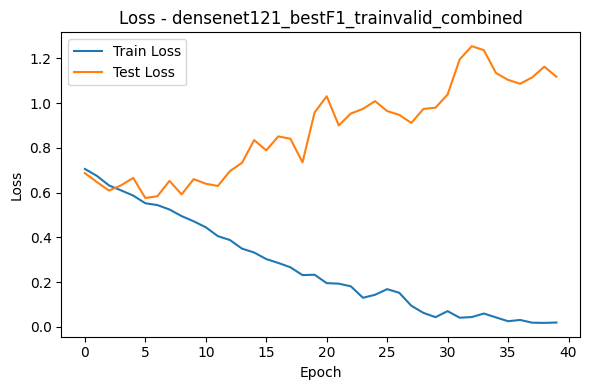


=== FINAL TEST METRICS (densenet121_bestF1_trainvalid_combined) ===
 accuracy: 0.6935
precision: 0.6033
   recall: 0.5703
       f1: 0.5863
      auc: 0.7520
Confusion Matrix (rows=true, cols=pred):
 [[160  48]
 [ 55  73]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/densenet121_bestF1_trainvalid_combined_test_metrics.csv

=== Training densenet121_bestACC_trainvalid_combined (densenet121) ===
[Epoch 01] train_loss=0.6649 train_acc=0.630 | test_loss=0.6662 test_acc=0.604
[Epoch 02] train_loss=0.6289 train_acc=0.664 | test_loss=0.6339 test_acc=0.655
[Epoch 03] train_loss=0.5988 train_acc=0.686 | test_loss=0.6374 test_acc=0.670
[Epoch 04] train_loss=0.5808 train_acc=0.703 | test_loss=0.6319 test_acc=0.664
[Epoch 05] train_loss=0.5385 train_acc=0.724 | test_loss=0.6330 test_acc=0.670
[Epoch 06] train_loss=0.5139 train_acc=0.749 | test_loss=0.6158 test_acc=0.688
[Epoch 07] train_loss=0.4848 train_acc=0.770 | test_loss=0.6363 test_acc=0.688
[Epoch 08] 

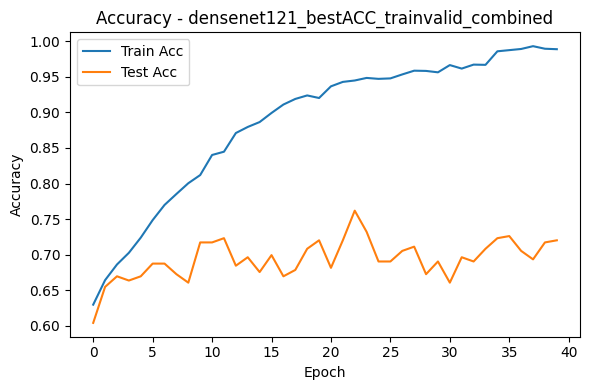

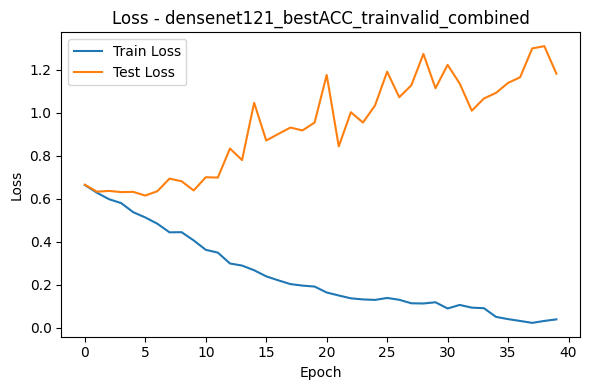


=== FINAL TEST METRICS (densenet121_bestACC_trainvalid_combined) ===
 accuracy: 0.6935
precision: 0.6471
   recall: 0.4297
       f1: 0.5164
      auc: 0.7483
Confusion Matrix (rows=true, cols=pred):
 [[178  30]
 [ 73  55]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/densenet121_bestACC_trainvalid_combined_test_metrics.csv

=== Side-by-side (Final Test) ===
 accuracy: BestF1=0.6935 | BestACC=0.6935
precision: BestF1=0.6033 | BestACC=0.6471
   recall: BestF1=0.5703 | BestACC=0.4297
       f1: BestF1=0.5863 | BestACC=0.5164
      auc: BestF1=0.7520 | BestACC=0.7483


In [ ]:
# ==============================#
# Step 5.1: Final train (DenseNet121 Best-F1 & Best-Accuracy) + per-epoch Test curves
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix)
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
from pathlib import Path

# ---- Save directory ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run_final')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Final outputs -> {SAVE_DIR.resolve()}")

# ---- Training budget ----
MAX_EPOCHS = 40
LOG_EVERY  = 0      # print batch progress
USE_SCHED  = True   # LR decay on train loss plateau

# ---- Two hypertuned configs (from your table) ----
CFG_BEST_F1 = {
    "tag": "densenet121_bestF1_trainvalid_combined",
    "model_name": "densenet121",
    "freeze": "train_all",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.2,
    "class_weighting": True,
}
CFG_BEST_ACC = {
    "tag": "densenet121_bestACC_trainvalid_combined",
    "model_name": "densenet121",
    "freeze": "freeze_block1",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.4,
    "class_weighting": False,
}
ALL_CFGS = [CFG_BEST_F1, CFG_BEST_ACC]

# -------------------- Model & Freeze (DenseNet121) -------------------- #
def build_model(dropout_p: float = 0.5) -> nn.Module:
    """ImageNet-pretrained DenseNet121 with binary head."""
    m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
    in_feats = m.classifier.in_features
    m.classifier = nn.Sequential(
        nn.Dropout(p=float(dropout_p)),
        nn.Linear(in_feats, 2)
    )
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str):
    """
    Freeze policy for DenseNet121.
      - 'freeze_block1': freeze very early stem + first dense block (+ transition1)
      - 'train_all'    : unfreeze everything
    """
    for p in model.parameters():
        p.requires_grad = True
    if mode == "freeze_block1":
        # Freeze up to and including denseblock1 & transition1 (early generic features)
        modules_to_freeze = [
            model.features.conv0,
            model.features.norm0,
            model.features.relu0,
            model.features.pool0,
            model.features.denseblock1,
            model.features.transition1,
        ]
        for m in modules_to_freeze:
            for p in m.parameters():
                p.requires_grad = False
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

# -------------------- Class Weights (from combined counts) -------------------- #
def count_targets_imgfolder(ds):
    counts = {c: 0 for c in ds.class_to_idx.values()}
    for _, y in ds.samples: counts[y] += 1
    return counts

def get_combined_class_weights():
    # Uses train_ds and valid_ds_eval from Step 4
    c_train = count_targets_imgfolder(train_ds)
    c_valid = count_targets_imgfolder(valid_ds_eval)
    combined = {k: c_train.get(k, 0) + c_valid.get(k, 0) for k in c_train.keys()}
    total = sum(combined.values())
    weights = [total / max(1, combined[c]) for c in sorted(combined.keys())]
    print("[INFO] Combined class counts:", {CLASS_NAMES[k]: v for k, v in sorted(combined.items())})
    print("[INFO] Class weights (inverse freq):", weights)
    return torch.tensor(weights, dtype=torch.float, device=DEVICE)

COMBINED_CLASS_WEIGHTS = get_combined_class_weights()

# -------------------- Train / Eval helpers -------------------- #
def train_one_epoch(model, loader, criterion, optimizer, epoch:int=1):
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for i, (xb, yb) in enumerate(loader, 1):
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

        if LOG_EVERY and (i % LOG_EVERY) == 0:
            print(f"  [Epoch {epoch:02d} | {i:05d} iters] loss={loss.item():.4f}")

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion):
    model.eval()
    loss_sum, seen, correct = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()
        seen += xb.size(0)
    return loss_sum / max(1, seen), correct / max(1, seen)

@torch.no_grad()
def evaluate_test_full(model, loader):
    model.eval()
    all_logits, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        all_logits.append(logits.cpu())
        all_targets.append(yb)
    logits = torch.cat(all_logits)
    y_true = torch.cat(all_targets).numpy()
    y_prob = torch.softmax(logits, dim=1).numpy()[:, 1]
    y_pred = logits.argmax(dim=1).numpy()

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = float('nan')
    cm = confusion_matrix(y_true, y_pred)
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc, "cm": cm}

def run_final_train(cfg):
    print(f"\n=== Training {cfg['tag']} ({cfg['model_name']}) ===")
    model = build_model(dropout_p=cfg["dropout"])
    freeze_strategy(model, cfg["freeze"])

    criterion = nn.CrossEntropyLoss(
        weight=COMBINED_CLASS_WEIGHTS if cfg["class_weighting"] else None
    )
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2) if USE_SCHED else None

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "lr": []}
    best_state = copy.deepcopy(model.state_dict())
    best_train_loss = math.inf

    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, epoch)
        te_loss, te_acc = evaluate_loss_acc(model, test_loader, criterion)  # per-epoch test eval

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        print(f"[Epoch {epoch:02d}] train_loss={tr_loss:.4f} train_acc={tr_acc:.3f} | "
              f"test_loss={te_loss:.4f} test_acc={te_acc:.3f}")

        if scheduler is not None:
            scheduler.step(tr_loss)

        if tr_loss < best_train_loss:
            best_train_loss = tr_loss
            best_state = copy.deepcopy(model.state_dict())

    train_time_min = (time.time() - t0) / 60.0
    print(f"[INFO] Training done in {train_time_min:.2f} min. Best train loss={best_train_loss:.4f}")

    # Load best-by-train-loss
    model.load_state_dict(best_state)

    # Save model
    final_model_path = SAVE_DIR / f"final_{cfg['tag']}.pth"
    torch.save({"state_dict": model.state_dict(), "hparams": cfg, "history": history}, final_model_path)
    print(f"[INFO] Saved final model to: {final_model_path}")

    # ---- Curves: Train vs Test ----
    # Accuracy
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["test_acc"],  label="Test Acc")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"Accuracy - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_acc_train_vs_test.png", dpi=150); plt.show()

    # Loss
    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["test_loss"],  label="Test Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"Loss - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_loss_train_vs_test.png", dpi=150); plt.show()

    # Final Test evaluation (full metrics with AUC/CM)
    test_metrics = evaluate_test_full(model, test_loader)
    print(f"\n=== FINAL TEST METRICS ({cfg['tag']}) ===")
    for k in ["accuracy", "precision", "recall", "f1", "auc"]:
        print(f"{k:>9}: {test_metrics[k]:.4f}")
    print("Confusion Matrix (rows=true, cols=pred):\n", test_metrics["cm"])

    # Save metrics CSV
    import pandas as pd
    pd.DataFrame([test_metrics | {"model": cfg['tag']}]).to_csv(
        SAVE_DIR / f"{cfg['tag']}_test_metrics.csv", index=False
    )
    print(f"[INFO] Wrote test metrics CSV: {SAVE_DIR / f'{cfg['tag']}_test_metrics.csv'}")

    return test_metrics

# -------------------- Run both DenseNet121 configs -------------------- #
metrics_f1  = run_final_train(CFG_BEST_F1)
metrics_acc = run_final_train(CFG_BEST_ACC)

print("\n=== Side-by-side (Final Test) ===")
for k in ["accuracy", "precision", "recall", "f1", "auc"]:
    print(f"{k:>9}: BestF1={metrics_f1[k]:.4f} | BestACC={metrics_acc[k]:.4f}")


# VGG16

[INFO] Final outputs -> /content/drive/MyDrive/colab_models/simple_run_final
[INFO] Combined class counts: {'non-cancer': 2017, 'cancer': 1030}
[INFO] Class weights (inverse freq): [1.510659395141299, 2.958252427184466]

=== Training vgg16_bestF1_trainvalid_combined (vgg16) ===
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 228MB/s]


[Epoch 01] train_loss=0.7012 train_acc=0.553 | test_loss=0.7263 test_acc=0.473
[Epoch 02] train_loss=0.6916 train_acc=0.550 | test_loss=0.6776 test_acc=0.619
[Epoch 03] train_loss=0.6910 train_acc=0.549 | test_loss=0.6992 test_acc=0.432
[Epoch 04] train_loss=0.6891 train_acc=0.549 | test_loss=0.8009 test_acc=0.536
[Epoch 05] train_loss=0.6855 train_acc=0.575 | test_loss=0.6902 test_acc=0.601
[Epoch 06] train_loss=0.6915 train_acc=0.606 | test_loss=0.6997 test_acc=0.461
[Epoch 07] train_loss=0.6901 train_acc=0.547 | test_loss=0.6850 test_acc=0.488
[Epoch 08] train_loss=0.6919 train_acc=0.532 | test_loss=0.7156 test_acc=0.432
[Epoch 09] train_loss=0.6867 train_acc=0.568 | test_loss=0.6918 test_acc=0.521
[Epoch 10] train_loss=0.6776 train_acc=0.573 | test_loss=0.6835 test_acc=0.527
[Epoch 11] train_loss=0.6756 train_acc=0.574 | test_loss=0.6835 test_acc=0.485
[Epoch 12] train_loss=0.6671 train_acc=0.580 | test_loss=0.7031 test_acc=0.473
[Epoch 13] train_loss=0.6638 train_acc=0.590 | test_

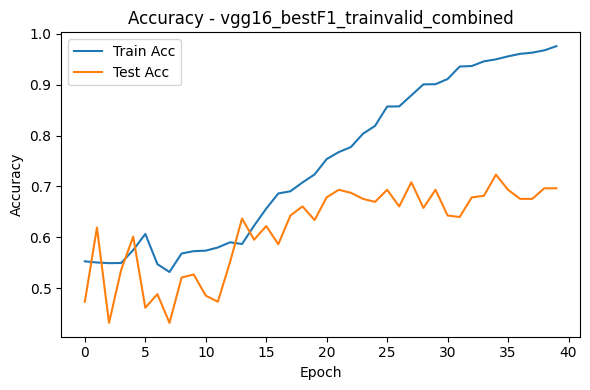

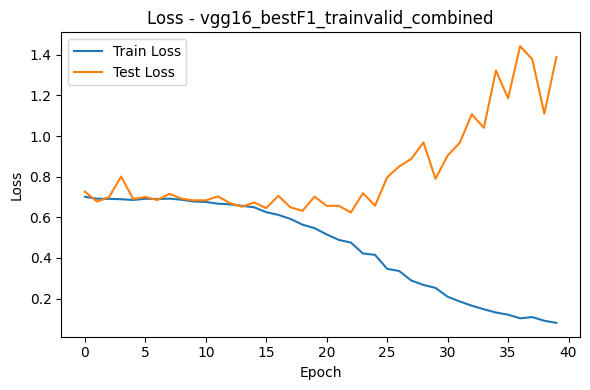


=== FINAL TEST METRICS (vgg16_bestF1_trainvalid_combined) ===
 accuracy: 0.6964
precision: 0.6140
   recall: 0.5469
       f1: 0.5785
      auc: 0.7389
Confusion Matrix (rows=true, cols=pred):
 [[164  44]
 [ 58  70]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/vgg16_bestF1_trainvalid_combined_test_metrics.csv

=== Training vgg16_bestACC_trainvalid_combined (vgg16) ===
[Epoch 01] train_loss=0.6482 train_acc=0.658 | test_loss=0.6640 test_acc=0.619
[Epoch 02] train_loss=0.6367 train_acc=0.660 | test_loss=0.6881 test_acc=0.619
[Epoch 03] train_loss=0.6438 train_acc=0.660 | test_loss=0.6636 test_acc=0.619
[Epoch 04] train_loss=0.6390 train_acc=0.662 | test_loss=0.6568 test_acc=0.619
[Epoch 05] train_loss=0.6331 train_acc=0.659 | test_loss=0.6609 test_acc=0.619
[Epoch 06] train_loss=0.6296 train_acc=0.659 | test_loss=0.6744 test_acc=0.619
[Epoch 07] train_loss=0.6298 train_acc=0.658 | test_loss=0.6597 test_acc=0.628
[Epoch 08] train_loss=0.6300 train_

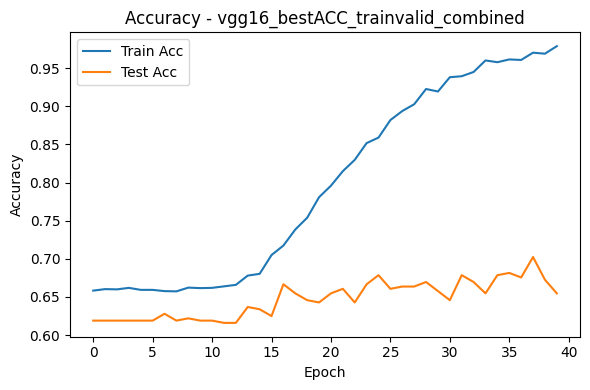

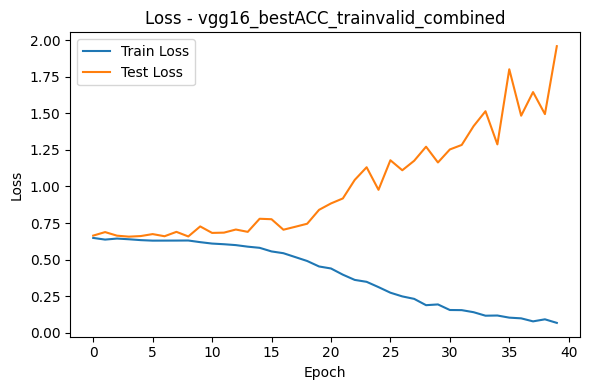


=== FINAL TEST METRICS (vgg16_bestACC_trainvalid_combined) ===
 accuracy: 0.6548
precision: 0.5508
   recall: 0.5078
       f1: 0.5285
      auc: 0.6998
Confusion Matrix (rows=true, cols=pred):
 [[155  53]
 [ 63  65]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/vgg16_bestACC_trainvalid_combined_test_metrics.csv

=== Side-by-side (Final Test) ===
 accuracy: BestF1=0.6964 | BestACC=0.6548
precision: BestF1=0.6140 | BestACC=0.5508
   recall: BestF1=0.5469 | BestACC=0.5078
       f1: BestF1=0.5785 | BestACC=0.5285
      auc: BestF1=0.7389 | BestACC=0.6998


In [ ]:
# ==============================#
# Step 5.1: Final train (VGG16 Best-F1 & Best-Accuracy) + per-epoch Test curves
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix)
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
from pathlib import Path

# ---- Save directory ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run_final')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Final outputs -> {SAVE_DIR.resolve()}")

# ---- Training budget ----
MAX_EPOCHS = 40
LOG_EVERY  = 0      # print batch progress
USE_SCHED  = True   # LR decay on train loss plateau

# ---- Two hypertuned configs (from your table) ----
CFG_BEST_F1 = {
    "tag": "vgg16_bestF1_trainvalid_combined",
    "model_name": "vgg16",
    "freeze": "train_all",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.2,
    "class_weighting": True,
}
CFG_BEST_ACC = {
    "tag": "vgg16_bestACC_trainvalid_combined",
    "model_name": "vgg16",
    "freeze": "freeze_block1",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.2,
    "class_weighting": False,
}
ALL_CFGS = [CFG_BEST_F1, CFG_BEST_ACC]

# -------------------- Model & Freeze (VGG16) -------------------- #
def build_model(dropout_p: float = 0.5) -> nn.Module:
    """ImageNet-pretrained VGG16 with a compact binary head."""
    m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    # Keep adaptive avgpool; replace classifier with Dropout + Linear(25088->2)
    in_feats = 512 * 7 * 7  # VGG16 default spatial size after avgpool for 224x224
    m.classifier = nn.Sequential(
        nn.Dropout(p=float(dropout_p)),
        nn.Linear(in_feats, 2)
    )
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str):
    """
    Freeze policy for VGG16.
      - 'freeze_block1': freeze the first conv block (conv1_1, relu, conv1_2, relu, maxpool)
      - 'train_all'    : unfreeze everything
    """
    for p in model.parameters():
        p.requires_grad = True
    if mode == "freeze_block1":
        # VGG16 features is Sequential: [conv, relu, conv, relu, pool] = block1
        for p in model.features[:5].parameters():
            p.requires_grad = False
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

# -------------------- Class Weights (from combined counts) -------------------- #
def count_targets_imgfolder(ds):
    counts = {c: 0 for c in ds.class_to_idx.values()}
    for _, y in ds.samples: counts[y] += 1
    return counts

def get_combined_class_weights():
    # Uses train_ds and valid_ds_eval from Step 4
    c_train = count_targets_imgfolder(train_ds)
    c_valid = count_targets_imgfolder(valid_ds_eval)
    combined = {k: c_train.get(k, 0) + c_valid.get(k, 0) for k in c_train.keys()}
    total = sum(combined.values())
    weights = [total / max(1, combined[c]) for c in sorted(combined.keys())]
    print("[INFO] Combined class counts:", {CLASS_NAMES[k]: v for k, v in sorted(combined.items())})
    print("[INFO] Class weights (inverse freq):", weights)
    return torch.tensor(weights, dtype=torch.float, device=DEVICE)

COMBINED_CLASS_WEIGHTS = get_combined_class_weights()

# -------------------- Train / Eval helpers -------------------- #
def train_one_epoch(model, loader, criterion, optimizer, epoch:int=1):
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for i, (xb, yb) in enumerate(loader, 1):
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

        if LOG_EVERY and (i % LOG_EVERY) == 0:
            print(f"  [Epoch {epoch:02d} | {i:05d} iters] loss={loss.item():.4f}")

    return running_loss / max(1, seen), running_correct / max(1, seen)

@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion):
    model.eval()
    loss_sum, seen, correct = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()
        seen += xb.size(0)
    return loss_sum / max(1, seen), correct / max(1, seen)

@torch.no_grad()
def evaluate_test_full(model, loader):
    model.eval()
    all_logits, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        all_logits.append(logits.cpu())
        all_targets.append(yb)
    logits = torch.cat(all_logits)
    y_true = torch.cat(all_targets).numpy()
    y_prob = torch.softmax(logits, dim=1).numpy()[:, 1]
    y_pred = logits.argmax(dim=1).numpy()

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = float('nan')
    cm = confusion_matrix(y_true, y_pred)
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc, "cm": cm}

def run_final_train(cfg):
    print(f"\n=== Training {cfg['tag']} ({cfg['model_name']}) ===")
    model = build_model(dropout_p=cfg["dropout"])
    freeze_strategy(model, cfg["freeze"])

    criterion = nn.CrossEntropyLoss(
        weight=COMBINED_CLASS_WEIGHTS if cfg["class_weighting"] else None
    )
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2) if USE_SCHED else None

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "lr": []}
    best_state = copy.deepcopy(model.state_dict())
    best_train_loss = math.inf

    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, epoch)
        te_loss, te_acc = evaluate_loss_acc(model, test_loader, criterion)  # per-epoch test eval

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        print(f"[Epoch {epoch:02d}] train_loss={tr_loss:.4f} train_acc={tr_acc:.3f} | "
              f"test_loss={te_loss:.4f} test_acc={te_acc:.3f}")

        if scheduler is not None:
            scheduler.step(tr_loss)

        if tr_loss < best_train_loss:
            best_train_loss = tr_loss
            best_state = copy.deepcopy(model.state_dict())

    train_time_min = (time.time() - t0) / 60.0
    print(f"[INFO] Training done in {train_time_min:.2f} min. Best train loss={best_train_loss:.4f}")

    # Load best-by-train-loss
    model.load_state_dict(best_state)

    # Save model
    final_model_path = SAVE_DIR / f"final_{cfg['tag']}.pth"
    torch.save({"state_dict": model.state_dict(), "hparams": cfg, "history": history}, final_model_path)
    print(f"[INFO] Saved final model to: {final_model_path}")

    # ---- Curves: Train vs Test ----
    # Accuracy
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["test_acc"],  label="Test Acc")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"Accuracy - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_acc_train_vs_test.png", dpi=150); plt.show()

    # Loss
    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["test_loss"],  label="Test Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"Loss - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_loss_train_vs_test.png", dpi=150); plt.show()

    # Final Test evaluation (full metrics with AUC/CM)
    test_metrics = evaluate_test_full(model, test_loader)
    print(f"\n=== FINAL TEST METRICS ({cfg['tag']}) ===")
    for k in ["accuracy", "precision", "recall", "f1", "auc"]:
        print(f"{k:>9}: {test_metrics[k]:.4f}")
    print("Confusion Matrix (rows=true, cols=pred):\n", test_metrics["cm"])

    # Save metrics CSV
    import pandas as pd
    pd.DataFrame([test_metrics | {"model": cfg['tag']}]).to_csv(
        SAVE_DIR / f"{cfg['tag']}_test_metrics.csv", index=False
    )
    print(f"[INFO] Wrote test metrics CSV: {SAVE_DIR / f'{cfg['tag']}_test_metrics.csv'}")

    return test_metrics

# -------------------- Run both VGG16 configs -------------------- #
metrics_f1  = run_final_train(CFG_BEST_F1)
metrics_acc = run_final_train(CFG_BEST_ACC)

print("\n=== Side-by-side (Final Test) ===")
for k in ["accuracy", "precision", "recall", "f1", "auc"]:
    print(f"{k:>9}: BestF1={metrics_f1[k]:.4f} | BestACC={metrics_acc[k]:.4f}")


# ConvNext

[INFO] Final outputs -> /content/drive/MyDrive/colab_models/simple_run_final
[INFO] Combined class counts: {'non-cancer': 2017, 'cancer': 1030}
[INFO] Class weights (inverse freq): [1.510659395141299, 2.958252427184466]

=== Training convnext_small_bestF1_trainvalid_combined (convnext_small) ===
[Epoch 01] train_loss=0.6477 train_acc=0.643 | test_loss=0.6370 test_acc=0.631
[Epoch 02] train_loss=0.6179 train_acc=0.660 | test_loss=0.6144 test_acc=0.658
[Epoch 03] train_loss=0.5887 train_acc=0.689 | test_loss=0.6460 test_acc=0.658
[Epoch 04] train_loss=0.5843 train_acc=0.698 | test_loss=0.5804 test_acc=0.685
[Epoch 05] train_loss=0.5532 train_acc=0.716 | test_loss=0.6185 test_acc=0.682
[Epoch 06] train_loss=0.5322 train_acc=0.742 | test_loss=0.6411 test_acc=0.676
[Epoch 07] train_loss=0.4984 train_acc=0.759 | test_loss=0.5982 test_acc=0.711
[Epoch 08] train_loss=0.4483 train_acc=0.793 | test_loss=0.6450 test_acc=0.720
[Epoch 09] train_loss=0.4168 train_acc=0.815 | test_loss=0.7078 test_ac

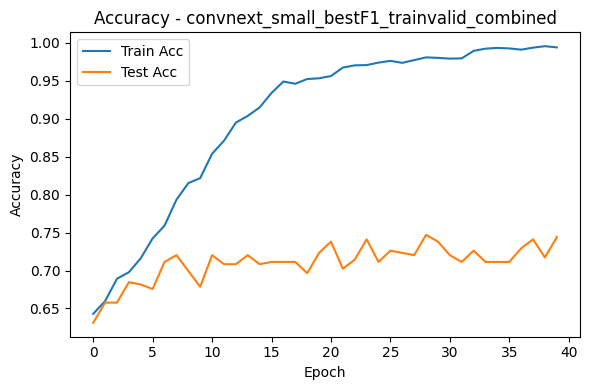

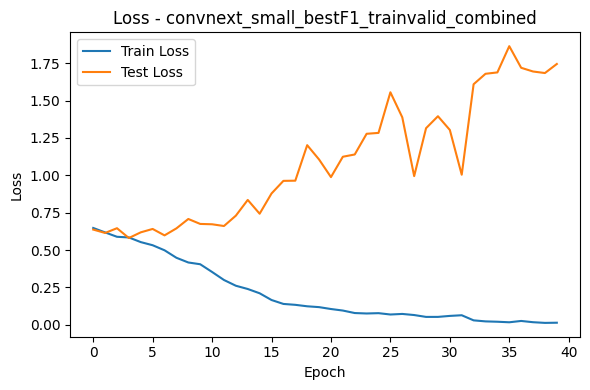


=== FINAL TEST METRICS (convnext_small_bestF1_trainvalid_combined) ===
 accuracy: 0.7173
precision: 0.6774
   recall: 0.4922
       f1: 0.5701
      auc: 0.7546
Confusion Matrix (rows=true, cols=pred):
 [[178  30]
 [ 65  63]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/convnext_small_bestF1_trainvalid_combined_test_metrics.csv

=== Training convnext_small_bestACC_trainvalid_combined (convnext_small) ===
[Epoch 01] train_loss=0.6567 train_acc=0.641 | test_loss=0.6685 test_acc=0.619
[Epoch 02] train_loss=0.6370 train_acc=0.651 | test_loss=0.6410 test_acc=0.628
[Epoch 03] train_loss=0.6177 train_acc=0.665 | test_loss=0.6231 test_acc=0.670
[Epoch 04] train_loss=0.6010 train_acc=0.681 | test_loss=0.6613 test_acc=0.619
[Epoch 05] train_loss=0.5772 train_acc=0.699 | test_loss=0.6281 test_acc=0.646
[Epoch 06] train_loss=0.5620 train_acc=0.701 | test_loss=0.6302 test_acc=0.661
[Epoch 07] train_loss=0.5366 train_acc=0.732 | test_loss=0.5922 test_acc=0.685

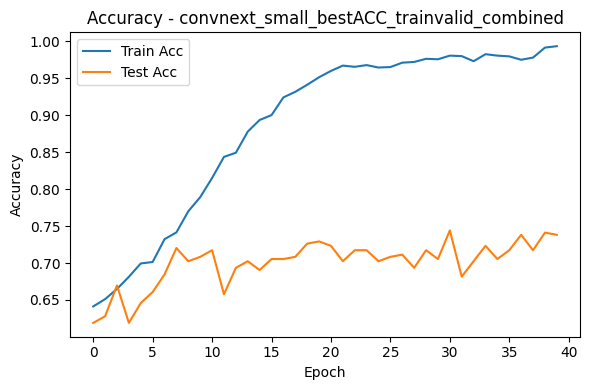

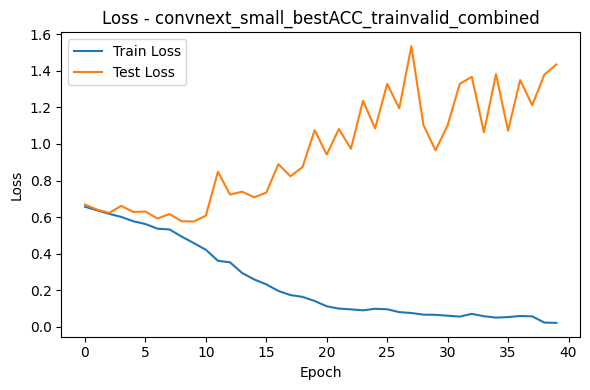


=== FINAL TEST METRICS (convnext_small_bestACC_trainvalid_combined) ===
 accuracy: 0.7381
precision: 0.6887
   recall: 0.5703
       f1: 0.6239
      auc: 0.7703
Confusion Matrix (rows=true, cols=pred):
 [[175  33]
 [ 55  73]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/convnext_small_bestACC_trainvalid_combined_test_metrics.csv

=== Side-by-side (Final Test) ===
 accuracy: BestF1=0.7173 | BestACC=0.7381
precision: BestF1=0.6774 | BestACC=0.6887
   recall: BestF1=0.4922 | BestACC=0.5703
       f1: BestF1=0.5701 | BestACC=0.6239
      auc: BestF1=0.7546 | BestACC=0.7703


In [ ]:
# ==============================#
# Step 5.1: Final train (ConvNeXt-Small Best-F1 & Best-Accuracy) + per-epoch Test curves
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix)
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
from pathlib import Path

# ---- Save directory ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run_final')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Final outputs -> {SAVE_DIR.resolve()}")

# ---- Training budget ----
MAX_EPOCHS = 40
LOG_EVERY  = 0      # print batch progress
USE_SCHED  = True   # LR decay on train loss plateau

# ---- Two hypertuned configs (from your table) ----
CFG_BEST_F1 = {
    "tag": "convnext_small_bestF1_trainvalid_combined",
    "model_name": "convnext_small",
    "freeze": "train_all",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.2,
    "class_weighting": False,
}
CFG_BEST_ACC = {
    "tag": "convnext_small_bestACC_trainvalid_combined",
    "model_name": "convnext_small",
    "freeze": "train_all",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.4,
    "class_weighting": False,
}
ALL_CFGS = [CFG_BEST_F1, CFG_BEST_ACC]

# -------------------- Model & Freeze (ConvNeXt-Small) -------------------- #
def build_model(dropout_p: float = 0.5) -> nn.Module:
    """ImageNet-pretrained ConvNeXt-Small with a binary head + dropout."""
    m = models.convnext_small(weights=models.ConvNeXt_Small_Weights.IMAGENET1K_V1)
    # m.classifier = [LayerNorm2d, Flatten, Linear(768->1000)] in torchvision
    in_feats = m.classifier[2].in_features
    m.classifier = nn.Sequential(
        m.classifier[0],       # LayerNorm2d
        m.classifier[1],       # Flatten(1)
        nn.Dropout(p=float(dropout_p)),
        nn.Linear(in_feats, 2)
    )
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str):
    """
    Freeze policy for ConvNeXt.
      - 'train_all'    : unfreeze everything (your two configs use this)
      - 'freeze_block1': optional—freeze early stem + first stage
    """
    for p in model.parameters():
        p.requires_grad = True
    if mode == "freeze_block1":
        # Freeze stem + stage 0 (early features)
        modules_to_freeze = [model.features[0], model.features[1]]  # stem + first downsample/stage
        for m in modules_to_freeze:
            for p in m.parameters():
                p.requires_grad = False
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

# -------------------- Class Weights from combined counts -------------------- #
def count_targets_imgfolder(ds):
    counts = {c: 0 for c in ds.class_to_idx.values()}
    for _, y in ds.samples: counts[y] += 1
    return counts

def get_combined_class_weights():
    # Uses train_ds and valid_ds_eval from Step 4
    c_train = count_targets_imgfolder(train_ds)
    c_valid = count_targets_imgfolder(valid_ds_eval)
    combined = {k: c_train.get(k, 0) + c_valid.get(k, 0) for k in c_train.keys()}
    total = sum(combined.values())
    weights = [total / max(1, combined[c]) for c in sorted(combined.keys())]
    print("[INFO] Combined class counts:", {CLASS_NAMES[k]: v for k, v in sorted(combined.items())})
    print("[INFO] Class weights (inverse freq):", weights)
    return torch.tensor(weights, dtype=torch.float, device=DEVICE)

COMBINED_CLASS_WEIGHTS = get_combined_class_weights()

# -------------------- Train / Eval helpers -------------------- #
def train_one_epoch(model, loader, criterion, optimizer, epoch:int=1):
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for i, (xb, yb) in enumerate(loader, 1):
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

        if LOG_EVERY and (i % LOG_EVERY) == 0:
            print(f"  [Epoch {epoch:02d} | {i:05d} iters] loss={loss.item():.4f}")

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion):
    model.eval()
    loss_sum, seen, correct = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()
        seen += xb.size(0)
    return loss_sum / max(1, seen), correct / max(1, seen)

@torch.no_grad()
def evaluate_test_full(model, loader):
    model.eval()
    all_logits, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        all_logits.append(logits.cpu())
        all_targets.append(yb)
    logits = torch.cat(all_logits)
    y_true = torch.cat(all_targets).numpy()
    y_prob = torch.softmax(logits, dim=1).numpy()[:, 1]
    y_pred = logits.argmax(dim=1).numpy()

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = float('nan')
    cm = confusion_matrix(y_true, y_pred)
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc, "cm": cm}

def run_final_train(cfg):
    print(f"\n=== Training {cfg['tag']} ({cfg['model_name']}) ===")
    model = build_model(dropout_p=cfg["dropout"])
    freeze_strategy(model, cfg["freeze"])

    # Both configs use class_weighting=False -> plain CE
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2) if USE_SCHED else None

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "lr": []}
    best_state = copy.deepcopy(model.state_dict())
    best_train_loss = math.inf

    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, epoch)
        te_loss, te_acc = evaluate_loss_acc(model, test_loader, criterion)  # per-epoch test eval

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        print(f"[Epoch {epoch:02d}] train_loss={tr_loss:.4f} train_acc={tr_acc:.3f} | "
              f"test_loss={te_loss:.4f} test_acc={te_acc:.3f}")

        if scheduler is not None:
            scheduler.step(tr_loss)

        if tr_loss < best_train_loss:
            best_train_loss = tr_loss
            best_state = copy.deepcopy(model.state_dict())

    train_time_min = (time.time() - t0) / 60.0
    print(f"[INFO] Training done in {train_time_min:.2f} min. Best train loss={best_train_loss:.4f}")

    # Load best-by-train-loss
    model.load_state_dict(best_state)

    # Save model
    final_model_path = SAVE_DIR / f"final_{cfg['tag']}.pth"
    torch.save({"state_dict": model.state_dict(), "hparams": cfg, "history": history}, final_model_path)
    print(f"[INFO] Saved final model to: {final_model_path}")

    # ---- Curves: Train vs Test ----
    # Accuracy
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["test_acc"],  label="Test Acc")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"Accuracy - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_acc_train_vs_test.png", dpi=150); plt.show()

    # Loss
    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["test_loss"],  label="Test Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"Loss - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_loss_train_vs_test.png", dpi=150); plt.show()

    # Final Test evaluation (full metrics with AUC/CM)
    test_metrics = evaluate_test_full(model, test_loader)
    print(f"\n=== FINAL TEST METRICS ({cfg['tag']}) ===")
    for k in ["accuracy", "precision", "recall", "f1", "auc"]:
        print(f"{k:>9}: {test_metrics[k]:.4f}")
    print("Confusion Matrix (rows=true, cols=pred):\n", test_metrics["cm"])

    # Save metrics CSV
    import pandas as pd
    pd.DataFrame([test_metrics | {"model": cfg['tag']}]).to_csv(
        SAVE_DIR / f"{cfg['tag']}_test_metrics.csv", index=False
    )
    print(f"[INFO] Wrote test metrics CSV: {SAVE_DIR / f'{cfg['tag']}_test_metrics.csv'}")

    return test_metrics

# -------------------- Run both ConvNeXt-Small configs -------------------- #
metrics_f1  = run_final_train(CFG_BEST_F1)
metrics_acc = run_final_train(CFG_BEST_ACC)

print("\n=== Side-by-side (Final Test) ===")
for k in ["accuracy", "precision", "recall", "f1", "auc"]:
    print(f"{k:>9}: BestF1={metrics_f1[k]:.4f} | BestACC={metrics_acc[k]:.4f}")


# EfficientNet

[INFO] Final outputs -> /content/drive/MyDrive/colab_models/simple_run_final
[INFO] Combined class counts: {'non-cancer': 2017, 'cancer': 1030}
[INFO] Class weights (inverse freq): [1.510659395141299, 2.958252427184466]

=== Training efficientnet_v2_s_bestF1_trainvalid_combined (efficientnet_v2_s) ===
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 220MB/s]


[Epoch 01] train_loss=0.6874 train_acc=0.568 | test_loss=0.6745 test_acc=0.545
[Epoch 02] train_loss=0.6655 train_acc=0.594 | test_loss=0.6379 test_acc=0.652
[Epoch 03] train_loss=0.6336 train_acc=0.647 | test_loss=0.6670 test_acc=0.580
[Epoch 04] train_loss=0.6119 train_acc=0.681 | test_loss=0.6549 test_acc=0.601
[Epoch 05] train_loss=0.5680 train_acc=0.708 | test_loss=0.6279 test_acc=0.673
[Epoch 06] train_loss=0.5327 train_acc=0.736 | test_loss=0.6318 test_acc=0.679
[Epoch 07] train_loss=0.4845 train_acc=0.765 | test_loss=0.6328 test_acc=0.720
[Epoch 08] train_loss=0.4507 train_acc=0.797 | test_loss=0.6357 test_acc=0.702
[Epoch 09] train_loss=0.4065 train_acc=0.818 | test_loss=0.6636 test_acc=0.679
[Epoch 10] train_loss=0.3519 train_acc=0.845 | test_loss=0.7165 test_acc=0.682
[Epoch 11] train_loss=0.3161 train_acc=0.867 | test_loss=0.7055 test_acc=0.717
[Epoch 12] train_loss=0.2669 train_acc=0.891 | test_loss=0.8047 test_acc=0.696
[Epoch 13] train_loss=0.2677 train_acc=0.896 | test_

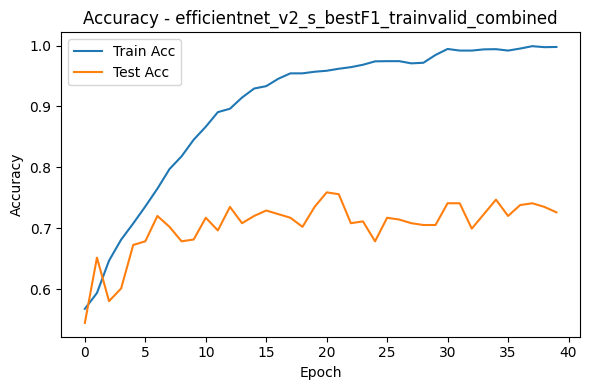

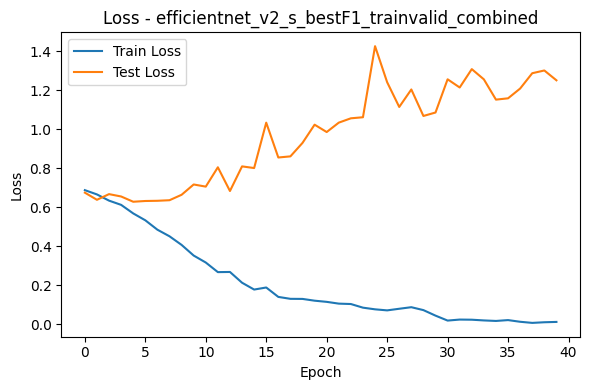


=== FINAL TEST METRICS (efficientnet_v2_s_bestF1_trainvalid_combined) ===
 accuracy: 0.7411
precision: 0.6541
   recall: 0.6797
       f1: 0.6667
      auc: 0.8027
Confusion Matrix (rows=true, cols=pred):
 [[162  46]
 [ 41  87]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/efficientnet_v2_s_bestF1_trainvalid_combined_test_metrics.csv

=== Training efficientnet_v2_s_bestACC_trainvalid_combined (efficientnet_v2_s) ===
[Epoch 01] train_loss=0.6473 train_acc=0.639 | test_loss=0.6631 test_acc=0.613
[Epoch 02] train_loss=0.6214 train_acc=0.659 | test_loss=0.6221 test_acc=0.655
[Epoch 03] train_loss=0.5832 train_acc=0.687 | test_loss=0.6876 test_acc=0.625
[Epoch 04] train_loss=0.5545 train_acc=0.725 | test_loss=0.6622 test_acc=0.646
[Epoch 05] train_loss=0.5203 train_acc=0.739 | test_loss=0.6229 test_acc=0.664
[Epoch 06] train_loss=0.4852 train_acc=0.764 | test_loss=0.6681 test_acc=0.711
[Epoch 07] train_loss=0.4574 train_acc=0.789 | test_loss=0.5620 te

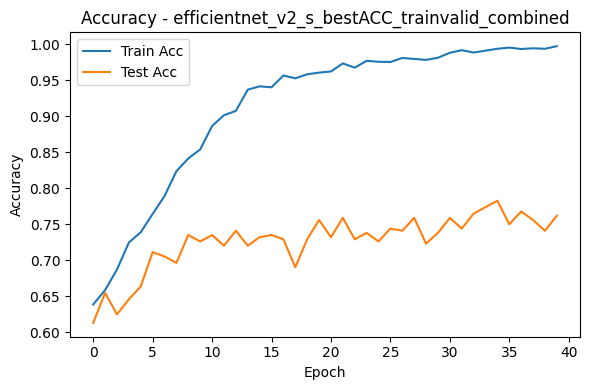

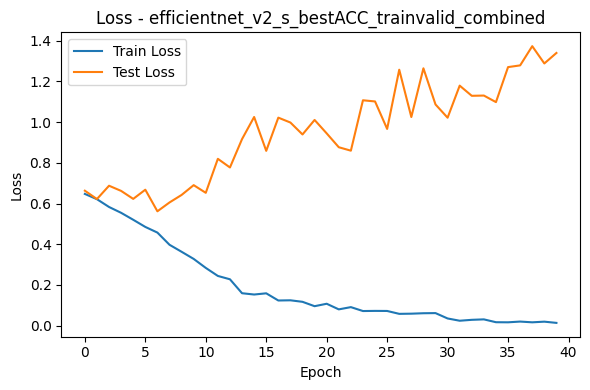


=== FINAL TEST METRICS (efficientnet_v2_s_bestACC_trainvalid_combined) ===
 accuracy: 0.7619
precision: 0.7727
   recall: 0.5312
       f1: 0.6296
      auc: 0.8078
Confusion Matrix (rows=true, cols=pred):
 [[188  20]
 [ 60  68]]
[INFO] Wrote test metrics CSV: /content/drive/MyDrive/colab_models/simple_run_final/efficientnet_v2_s_bestACC_trainvalid_combined_test_metrics.csv

=== Side-by-side (Final Test) ===
 accuracy: BestF1=0.7411 | BestACC=0.7619
precision: BestF1=0.6541 | BestACC=0.7727
   recall: BestF1=0.6797 | BestACC=0.5312
       f1: BestF1=0.6667 | BestACC=0.6296
      auc: BestF1=0.8027 | BestACC=0.8078


In [ ]:
# ==============================#
# Step 5.1: Final train (EfficientNet-V2-S Best-F1 & Best-Accuracy) + per-epoch Test curves
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix)
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
from pathlib import Path

# ---- Save directory ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run_final')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Final outputs -> {SAVE_DIR.resolve()}")

# ---- Training budget ----
MAX_EPOCHS = 40
LOG_EVERY  = 0      # print batch progress
USE_SCHED  = True   # LR decay on train loss plateau

# ---- Two hypertuned configs (from your table) ----
CFG_BEST_F1 = {
    "tag": "efficientnet_v2_s_bestF1_trainvalid_combined",
    "model_name": "efficientnet_v2_s",
    "freeze": "freeze_block1",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.2,
    "class_weighting": True,
}
CFG_BEST_ACC = {
    "tag": "efficientnet_v2_s_bestACC_trainvalid_combined",
    "model_name": "efficientnet_v2_s",
    "freeze": "freeze_block1",
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.2,
    "class_weighting": False,
}
ALL_CFGS = [CFG_BEST_F1, CFG_BEST_ACC]

# -------------------- Model & Freeze (EfficientNet-V2-S) -------------------- #
def build_model(dropout_p: float = 0.5) -> nn.Module:
    """ImageNet-pretrained EfficientNet-V2-S with a binary head + dropout."""
    m = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
    # Replace classifier: default is [Dropout(0.2), Linear(1280->1000)]
    in_feats = m.classifier[1].in_features
    m.classifier = nn.Sequential(
        nn.Dropout(p=float(dropout_p)),
        nn.Linear(in_feats, 2)
    )
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str):
    """
    Freeze policy for EfficientNet-V2-S.
      - 'freeze_block1': freeze stem + first stage (early generic features)
      - 'train_all'    : unfreeze everything
    """
    for p in model.parameters():
        p.requires_grad = True
    if mode == "freeze_block1":
        # EfficientNet-V2-S: model.features is a Sequential of stages.
        # We freeze the stem (index 0) and first stage (index 1).
        modules_to_freeze = [model.features[0], model.features[1]]
        for m in modules_to_freeze:
            for p in m.parameters():
                p.requires_grad = False
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

# -------------------- Class Weights (from combined counts) -------------------- #
def count_targets_imgfolder(ds):
    counts = {c: 0 for c in ds.class_to_idx.values()}
    for _, y in ds.samples: counts[y] += 1
    return counts

def get_combined_class_weights():
    # Uses train_ds and valid_ds_eval from Step 4
    c_train = count_targets_imgfolder(train_ds)
    c_valid = count_targets_imgfolder(valid_ds_eval)
    combined = {k: c_train.get(k, 0) + c_valid.get(k, 0) for k in c_train.keys()}
    total = sum(combined.values())
    weights = [total / max(1, combined[c]) for c in sorted(combined.keys())]
    print("[INFO] Combined class counts:", {CLASS_NAMES[k]: v for k, v in sorted(combined.items())})
    print("[INFO] Class weights (inverse freq):", weights)
    return torch.tensor(weights, dtype=torch.float, device=DEVICE)

COMBINED_CLASS_WEIGHTS = get_combined_class_weights()

# -------------------- Train / Eval helpers -------------------- #
def train_one_epoch(model, loader, criterion, optimizer, epoch:int=1):
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for i, (xb, yb) in enumerate(loader, 1):
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

        if LOG_EVERY and (i % LOG_EVERY) == 0:
            print(f"  [Epoch {epoch:02d} | {i:05d} iters] loss={loss.item():.4f}")

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion):
    model.eval()
    loss_sum, seen, correct = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == yb).sum().item()
        seen += xb.size(0)
    return loss_sum / max(1, seen), correct / max(1, seen)

@torch.no_grad()
def evaluate_test_full(model, loader):
    model.eval()
    all_logits, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        all_logits.append(logits.cpu())
        all_targets.append(yb)
    logits = torch.cat(all_logits)
    y_true = torch.cat(all_targets).numpy()
    y_prob = torch.softmax(logits, dim=1).numpy()[:, 1]
    y_pred = logits.argmax(dim=1).numpy()

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = float('nan')
    cm = confusion_matrix(y_true, y_pred)
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc, "cm": cm}

def run_final_train(cfg):
    print(f"\n=== Training {cfg['tag']} ({cfg['model_name']}) ===")
    model = build_model(dropout_p=cfg["dropout"])
    freeze_strategy(model, cfg["freeze"])

    criterion = nn.CrossEntropyLoss(
        weight=COMBINED_CLASS_WEIGHTS if cfg["class_weighting"] else None
    )
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2) if USE_SCHED else None

    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "lr": []}
    best_state = copy.deepcopy(model.state_dict())
    best_train_loss = math.inf

    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, epoch)
        te_loss, te_acc = evaluate_loss_acc(model, test_loader, criterion)  # per-epoch test eval

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        print(f"[Epoch {epoch:02d}] train_loss={tr_loss:.4f} train_acc={tr_acc:.3f} | "
              f"test_loss={te_loss:.4f} test_acc={te_acc:.3f}")

        if scheduler is not None:
            scheduler.step(tr_loss)

        if tr_loss < best_train_loss:
            best_train_loss = tr_loss
            best_state = copy.deepcopy(model.state_dict())

    train_time_min = (time.time() - t0) / 60.0
    print(f"[INFO] Training done in {train_time_min:.2f} min. Best train loss={best_train_loss:.4f}")

    # Load best-by-train-loss
    model.load_state_dict(best_state)

    # Save model
    final_model_path = SAVE_DIR / f"final_{cfg['tag']}.pth"
    torch.save({"state_dict": model.state_dict(), "hparams": cfg, "history": history}, final_model_path)
    print(f"[INFO] Saved final model to: {final_model_path}")

    # ---- Curves: Train vs Test ----
    # Accuracy
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["test_acc"],  label="Test Acc")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"Accuracy - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_acc_train_vs_test.png", dpi=150); plt.show()

    # Loss
    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["test_loss"],  label="Test Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"Loss - {cfg['tag']}")
    plt.legend(); plt.tight_layout()
    plt.savefig(SAVE_DIR / f"{cfg['tag']}_loss_train_vs_test.png", dpi=150); plt.show()

    # Final Test evaluation (full metrics with AUC/CM)
    test_metrics = evaluate_test_full(model, test_loader)
    print(f"\n=== FINAL TEST METRICS ({cfg['tag']}) ===")
    for k in ["accuracy", "precision", "recall", "f1", "auc"]:
        print(f"{k:>9}: {test_metrics[k]:.4f}")
    print("Confusion Matrix (rows=true, cols=pred):\n", test_metrics["cm"])

    # Save metrics CSV
    import pandas as pd
    pd.DataFrame([test_metrics | {"model": cfg['tag']}]).to_csv(
        SAVE_DIR / f"{cfg['tag']}_test_metrics.csv", index=False
    )
    print(f"[INFO] Wrote test metrics CSV: {SAVE_DIR / f'{cfg['tag']}_test_metrics.csv'}")

    return test_metrics

# -------------------- Run both EfficientNet-V2-S configs -------------------- #
metrics_f1  = run_final_train(CFG_BEST_F1)
metrics_acc = run_final_train(CFG_BEST_ACC)

print("\n=== Side-by-side (Final Test) ===")
for k in ["accuracy", "precision", "recall", "f1", "auc"]:
    print(f"{k:>9}: BestF1={metrics_f1[k]:.4f} | BestACC={metrics_acc[k]:.4f}")


# Ensemble Model

In [ ]:
# ==============================#
# Step 6: Ensemble evaluation (Soft & Hard voting) on TEST set
# ==============================#
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix)
import numpy as np
import pandas as pd
from pathlib import Path

# ---- Where the .pth files are ----
ENSEMBLE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run_final')
OUT_DIR = ENSEMBLE_DIR
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- Helper: rebuild model with correct head/dropout (must match training) ----
def build_model(arch: str, dropout_p: float) -> nn.Module:
    arch = arch.lower()
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        m.fc = nn.Sequential(nn.Dropout(p=float(dropout_p)),
                             nn.Linear(m.fc.in_features, 2))
    elif arch == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        in_feats = m.classifier.in_features
        m.classifier = nn.Sequential(nn.Dropout(p=float(dropout_p)),
                                     nn.Linear(in_feats, 2))
    elif arch == "vgg16":
        m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        in_feats = 512 * 7 * 7
        m.classifier = nn.Sequential(nn.Dropout(p=float(dropout_p)),
                                     nn.Linear(in_feats, 2))
    elif arch == "convnext_small":
        m = models.convnext_small(weights=models.ConvNeXt_Small_Weights.IMAGENET1K_V1)
        in_feats = m.classifier[2].in_features
        m.classifier = nn.Sequential(
            m.classifier[0],   # LayerNorm2d
            m.classifier[1],   # Flatten
            nn.Dropout(p=float(dropout_p)),
            nn.Linear(in_feats, 2)
        )
    elif arch == "efficientnet_v2_s":
        m = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
        in_feats = m.classifier[1].in_features
        m.classifier = nn.Sequential(nn.Dropout(p=float(dropout_p)),
                                     nn.Linear(in_feats, 2))
    else:
        raise ValueError(f"Unknown arch: {arch}")
    return m.to(DEVICE)

# ----  two ensembles (paths + arch + dropout) ----
# Best Accuracy ensemble (all train_all at train time, but for inference only arch+dropout matter)
ACC_MODELS = [
    { "name": "convnext_small_bestACC",  "arch": "convnext_small",   "dropout": 0.4,
      "ckpt": ENSEMBLE_DIR / "final_convnext_small_bestACC_trainvalid_combined.pth"},
    { "name": "densenet121_bestACC",     "arch": "densenet121",      "dropout": 0.4,
      "ckpt": ENSEMBLE_DIR / "final_densenet121_bestACC_trainvalid_combined.pth"},
    { "name": "efficientnet_v2_s_bestACC","arch": "efficientnet_v2_s","dropout": 0.2,
      "ckpt": ENSEMBLE_DIR / "final_efficientnet_v2_s_bestACC_trainvalid_combined.pth"},
]

# Best F1 ensemble
F1_MODELS = [
    { "name": "densenet121_bestF1",      "arch": "densenet121",      "dropout": 0.2,
      "ckpt": ENSEMBLE_DIR / "final_densenet121_bestF1_trainvalid_combined.pth"},
    { "name": "efficientnet_v2_s_bestF1","arch": "efficientnet_v2_s","dropout": 0.2,
      "ckpt": ENSEMBLE_DIR / "final_efficientnet_v2_s_bestF1_trainvalid_combined.pth"},
    { "name": "vgg16_bestF1",            "arch": "vgg16",            "dropout": 0.2,
      "ckpt": ENSEMBLE_DIR / "final_vgg16_bestF1_trainvalid_combined.pth"},
]

# ---- Load a model and produce logits/probs/preds on the TEST set ----
@torch.no_grad()
def run_inference(arch: str, dropout: float, ckpt_path: Path, loader):
    model = build_model(arch, dropout)
    # Load only the state_dict, not the whole saved dict
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()

    all_logits, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        all_logits.append(logits.cpu())
        all_targets.append(yb)
    logits = torch.cat(all_logits)                        # [N,2]
    y_true = torch.cat(all_targets).numpy()               # [N]
    y_prob = torch.softmax(logits, dim=1).numpy()[:, 1]   # P(class=1)
    y_pred = logits.argmax(dim=1).numpy()                 # hard preds
    return y_true, y_prob, y_pred

def metrics_from_probs_preds(y_true, y_prob, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    try:
        auc = roc_auc_score(y_true, y_prob)
    except ValueError:
        auc = float('nan')
    cm = confusion_matrix(y_true, y_pred)
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc, "cm": cm}

# ---- Run per-model inference & collect outputs ----
def evaluate_group(name: str, model_specs, loader):
    per_model = {}
    y_true_ref = None
    probs = []
    hards = []

    print(f"\n=== Evaluating group: {name} ===")
    for spec in model_specs:
        y_true, y_prob, y_pred = run_inference(spec["arch"], spec["dropout"], spec["ckpt"], loader)
        if y_true_ref is None:
            y_true_ref = y_true
        else:
            assert np.array_equal(y_true_ref, y_true), "Test targets mismatch across runs"

        per_model[spec["name"]] = metrics_from_probs_preds(y_true, y_prob, y_pred)
        probs.append(y_prob.reshape(-1, 1))
        hards.append(y_pred.reshape(-1, 1))
        print(f"  -> {spec['name']}: "
              f"Acc={per_model[spec['name']]['accuracy']:.4f}, "
              f"F1={per_model[spec['name']]['f1']:.4f}, "
              f"AUC={per_model[spec['name']]['auc']:.4f}")

    # ---- Soft vote: mean probability ----
    P = np.concatenate(probs, axis=1)         # [N, K]
    y_prob_soft = P.mean(axis=1)
    y_pred_soft = (y_prob_soft >= 0.5).astype(int)
    soft_metrics = metrics_from_probs_preds(y_true_ref, y_prob_soft, y_pred_soft)
    print(f"  => SoftVote[{name}]: Acc={soft_metrics['accuracy']:.4f}, "
          f"F1={soft_metrics['f1']:.4f}, AUC={soft_metrics['auc']:.4f}")

    # ---- Hard vote: majority of class labels ----
    H = np.concatenate(hards, axis=1)         # [N, K]
    y_pred_hard = (H.sum(axis=1) >= (H.shape[1] // 2 + 1)).astype(int)  # majority for K=3
    # For AUC with hard vote, we reuse the soft probs
    hard_metrics = metrics_from_probs_preds(y_true_ref, y_prob_soft, y_pred_hard)
    print(f"  => HardVote[{name}]: Acc={hard_metrics['accuracy']:.4f}, "
          f"F1={hard_metrics['f1']:.4f}, AUC(using soft probs)={hard_metrics['auc']:.4f}")

    return per_model, soft_metrics, hard_metrics

# ---- Run both ensembles on test_loader ----
acc_models_stats, acc_soft, acc_hard = evaluate_group("BestAccuracy", ACC_MODELS, test_loader)
f1_models_stats,  f1_soft,  f1_hard  = evaluate_group("BestF1",       F1_MODELS,  test_loader)

# ---- Tabulate & save ----
rows = []
for name, stats in acc_models_stats.items():
    rows.append({"group":"BestAccuracy", "model":name, **{k:v for k,v in stats.items() if k!="cm"}})
rows.append({"group":"BestAccuracy", "model":"Ensemble_Soft", **{k:v for k,v in acc_soft.items() if k!="cm"}})
rows.append({"group":"BestAccuracy", "model":"Ensemble_Hard", **{k:v for k,v in acc_hard.items() if k!="cm"}})

for name, stats in f1_models_stats.items():
    rows.append({"group":"BestF1", "model":name, **{k:v for k,v in stats.items() if k!="cm"}})
rows.append({"group":"BestF1", "model":"Ensemble_Soft", **{k:v for k,v in f1_soft.items() if k!="cm"}})
rows.append({"group":"BestF1", "model":"Ensemble_Hard", **{k:v for k,v in f1_hard.items() if k!="cm"}})

df = pd.DataFrame(rows)
csv_path = OUT_DIR / "ensemble_test_metrics.csv"
df.to_csv(csv_path, index=False)
print(f"\n[INFO] Wrote ensemble summary CSV -> {csv_path}")

# Print confusion matrices for the two ensemble votes
print("\nConfusion Matrix — BestAccuracy (Soft):\n", acc_soft["cm"])
print("Confusion Matrix — BestAccuracy (Hard):\n", acc_hard["cm"])
print("\nConfusion Matrix — BestF1 (Soft):\n", f1_soft["cm"])
print("Confusion Matrix — BestF1 (Hard):\n", f1_hard["cm"])

print("\n=== Side-by-side Ensemble Comparison (Final Test) ===")
print(f"{'Metric':>9} | {'BestAccuracy Soft':>18} | {'BestAccuracy Hard':>18} | {'BestF1 Soft':>14} | {'BestF1 Hard':>14}")
print("-" * 9 + "-|-" + "-"*18 + "-|-" + "-"*18 + "-|-" + "-"*14 + "-|-" + "-"*14)
for k in ["accuracy", "precision", "recall", "f1", "auc"]:
    print(f"{k:>9}: | {acc_soft[k]:>18.4f} | {acc_hard[k]:>18.4f} | {f1_soft[k]:>14.4f} | {f1_hard[k]:>14.4f}")


=== Evaluating group: BestAccuracy ===
  -> convnext_small_bestACC: Acc=0.7381, F1=0.6239, AUC=0.7703
  -> densenet121_bestACC: Acc=0.6935, F1=0.5164, AUC=0.7483
  -> efficientnet_v2_s_bestACC: Acc=0.7619, F1=0.6296, AUC=0.8078
  => SoftVote[BestAccuracy]: Acc=0.7589, F1=0.6087, AUC=0.8220
  => HardVote[BestAccuracy]: Acc=0.7560, F1=0.6019, AUC(using soft probs)=0.8220

=== Evaluating group: BestF1 ===
  -> densenet121_bestF1: Acc=0.6935, F1=0.5863, AUC=0.7520
  -> efficientnet_v2_s_bestF1: Acc=0.7411, F1=0.6667, AUC=0.8027
  -> vgg16_bestF1: Acc=0.6964, F1=0.5785, AUC=0.7389
  => SoftVote[BestF1]: Acc=0.7619, F1=0.6800, AUC=0.7973
  => HardVote[BestF1]: Acc=0.7381, F1=0.6508, AUC(using soft probs)=0.7973

[INFO] Wrote ensemble summary CSV -> /content/drive/MyDrive/colab_models/simple_run_final/ensemble_test_metrics.csv

Confusion Matrix — BestAccuracy (Soft):
 [[192  16]
 [ 65  63]]
Confusion Matrix — BestAccuracy (Hard):
 [[192  16]
 [ 66  62]]

Confusion Matrix — BestF1 (Soft):
 [[